In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import math
import autoroot
from paper_plots.plot_config import set_plot_style

from src.utils.result_processing import MODEL_KEY_REGISTRY


font_size = 55
lw=4
figsize = (12,8)

# Apply consistent styling
set_plot_style(font_family='Times New Roman', font_size=font_size, figsize=figsize, palette='Spectral',legend_font_size=40)
# loss = 'val/rLoss1_epoch'
loss = 'train/rLoss_epoch.min'

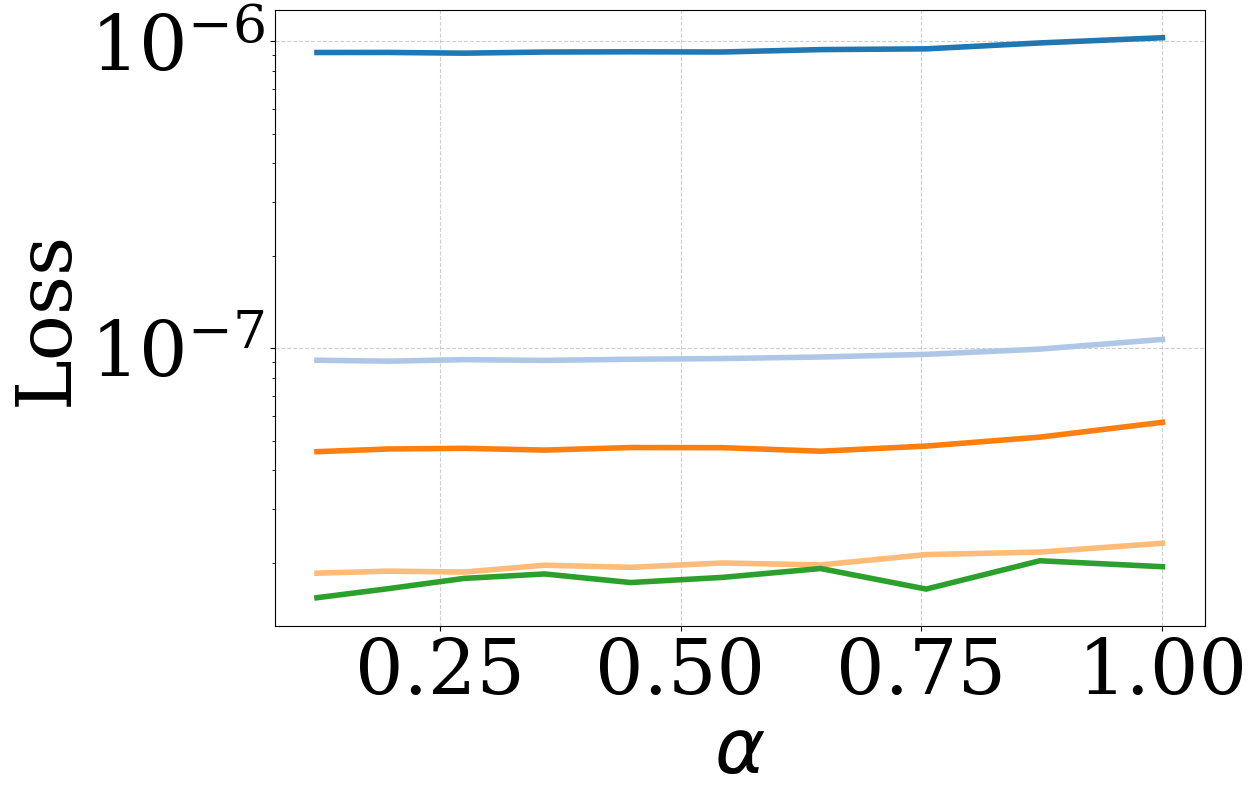

In [2]:

m_key = MODEL_KEY_REGISTRY['Mixed']
df = pd.read_pickle(f"../../results/Mixed_LSTM_Transformer_exp_experiment_data_clean.pkl")
df['m'] = df[m_key]
df['alpha'] = df['data.rho_param.alpha']/df['data.rho_param.alpha'].max()
df_min = df.groupby(['m', 'alpha'], as_index=False)[loss].min()


fig, ax1 = plt.subplots(figsize=figsize)
sns.lineplot(data=df_min, x='alpha', y=loss, hue='m', ax=ax1,
             palette='tab20', lw=lw, legend=False)



ax1.set_xlabel(r'$\alpha$')
# ax1.xaxis.set_label_coords(-0.08, 0.04)
ax1.set_yscale('log')
ax1.set_ylabel('Loss')
# ax1.set_ylim(1.1*1e-9, 0.8*1e-6)
plt.savefig('Mixed_LSTM_Transformer_exp.pdf', bbox_inches='tight')


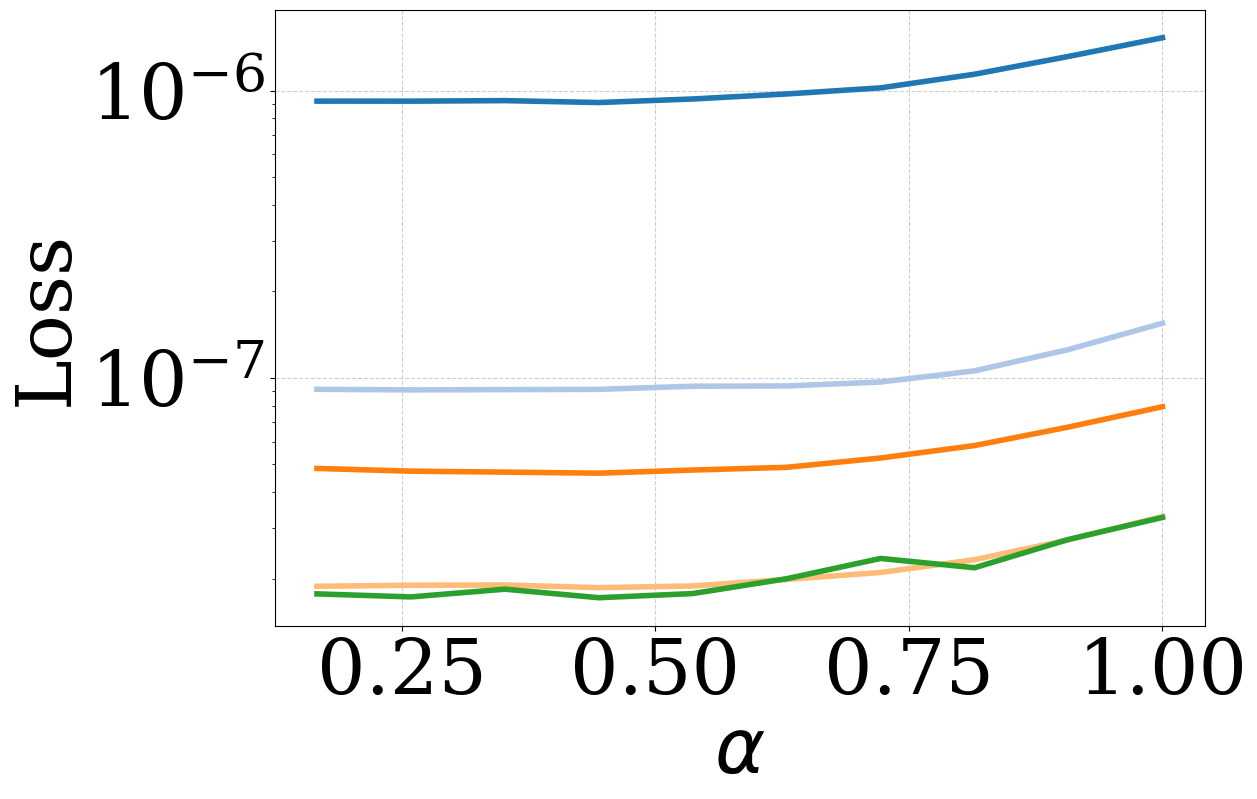

In [3]:
m_key = MODEL_KEY_REGISTRY['Mixed']
df = pd.read_pickle(f"../../results/Mixed_LSTM_Transformer_poly_experiment_data_clean.pkl")
df['m'] = df[m_key]
df['alpha'] = df['data.rho_param.alpha']/df['data.rho_param.alpha'].max()
df_min = df.groupby(['m', 'alpha'], as_index=False)[loss].min()


fig, ax1 = plt.subplots(figsize=figsize)
sns.lineplot(data=df_min, x='alpha', y=loss, hue='m', ax=ax1,
             palette='tab20', lw=lw, legend=False)



ax1.set_xlabel(r'$\alpha$')
# ax1.xaxis.set_label_coords(-0.08, 0.04)
ax1.set_yscale('log')

ax1.set_ylabel('Loss')
# ax1.set_ylim(1e-10, 0.8*1e-7)
plt.savefig('Mixed_LSTM_Transformer_poly.pdf', bbox_inches='tight')

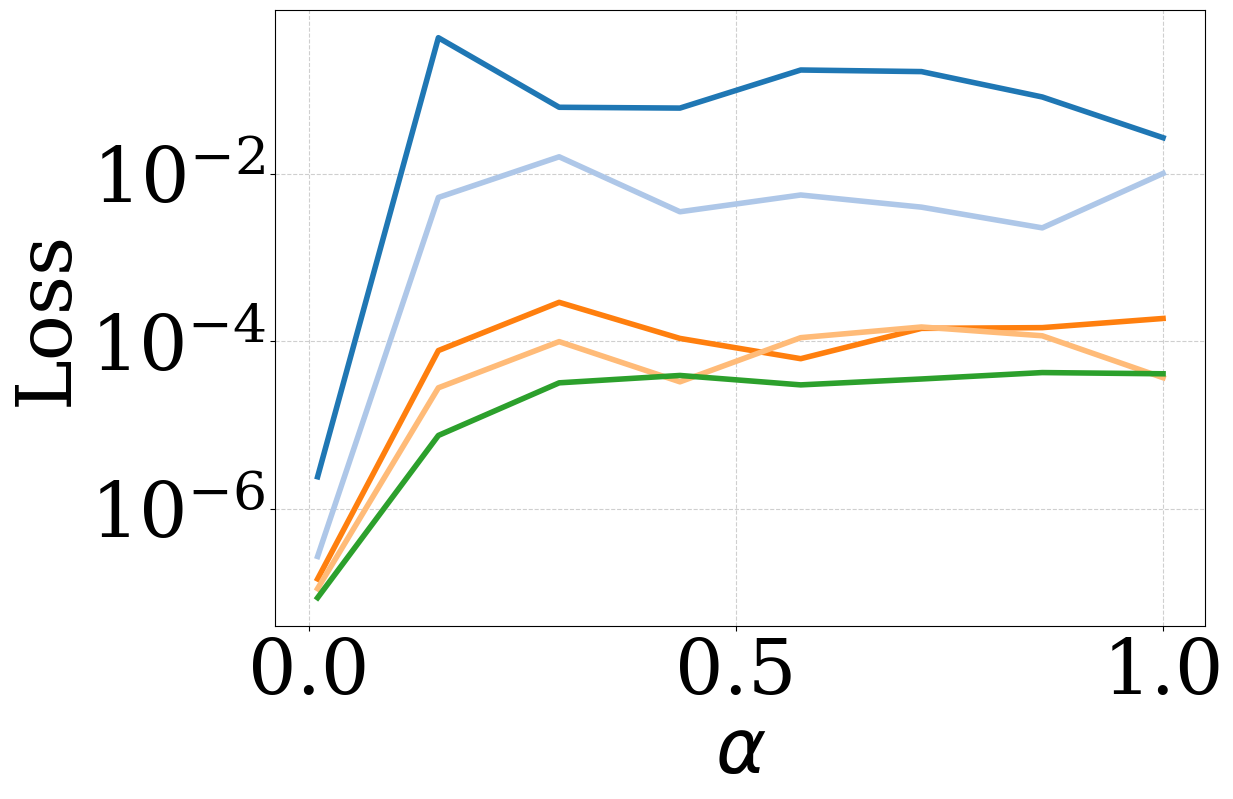

In [4]:
m_key = MODEL_KEY_REGISTRY['Mixed']
df = pd.read_pickle(f"../../results/Mixed_LSTM_Transformer_impulse_experiment_data_clean.pkl")
df['m'] = df[m_key]
df['alpha'] = df['data.rho_param.alpha']/df['data.rho_param.alpha'].max()
df[loss] = pd.to_numeric(df[loss], errors='coerce') 
df_min = df.groupby(['m', 'alpha'], as_index=False)[loss].min()


fig, ax1 = plt.subplots(figsize=figsize)
sns.lineplot(data=df_min, x='alpha', y=loss, hue='m', ax=ax1,
             palette='tab20', lw=lw, legend=False)



ax1.set_xlabel(r'$\alpha$')
# ax1.xaxis.set_label_coords(-0.08, 0.04)
ax1.set_yscale('log')

ax1.set_ylabel('Loss')
# ax1.set_ylim(1e-10, 0.8*1e-7)
plt.savefig('Mixed_LSTM_Transformer_impulse.pdf', bbox_inches='tight')

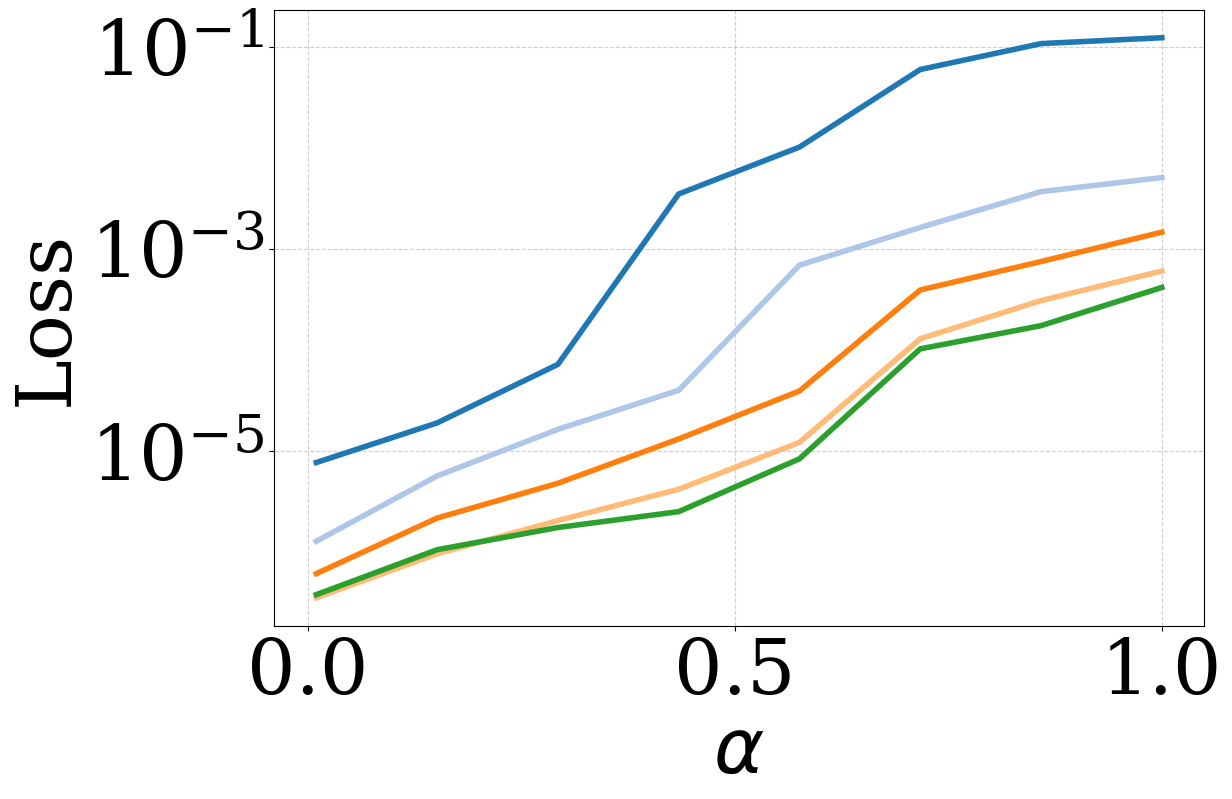

In [5]:
m_key = MODEL_KEY_REGISTRY['Mixed']
df = pd.read_pickle(f"../../results/Mixed_LSTM_Transformer_airy_experiment_data_clean.pkl")
df['m'] = df[m_key]
df['alpha'] = df['data.rho_param.alpha']/df['data.rho_param.alpha'].max()
df_min = df.groupby(['m', 'alpha'], as_index=False)[loss].min()


fig, ax1 = plt.subplots(figsize=figsize)
sns.lineplot(data=df_min, x='alpha', y=loss, hue='m', ax=ax1,
             palette='tab20', lw=lw, legend=False)



ax1.set_xlabel(r'$\alpha$')
# ax1.xaxis.set_label_coords(-0.08, 0.04)
ax1.set_yscale('log')

ax1.set_ylabel('Loss')
# ax1.set_ylim(1e-10, 0.8*1e-7)
plt.savefig('Mixed_LSTM_Transformer_airy.pdf', bbox_inches='tight')

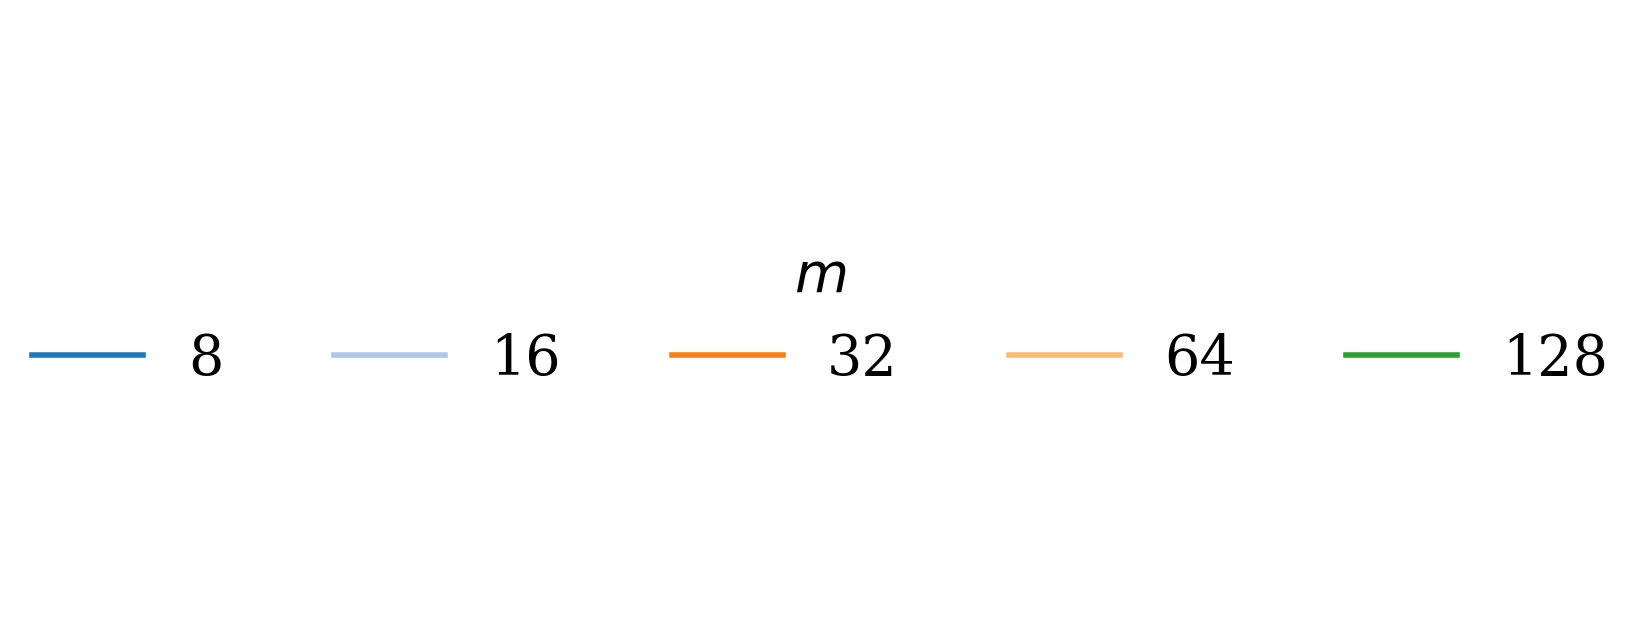

In [6]:
# Create a plot with just the legend
m_key = MODEL_KEY_REGISTRY['Mixed']
df = pd.read_pickle(f"../../results/Mixed_LSTM_Transformer_exp_experiment_data_clean.pkl")
df['m'] = df[m_key]
df['alpha'] = df['data.rho_param.alpha']/df['data.rho_param.alpha'].max()
df_min = df.groupby(['m', 'alpha'], as_index=False)[loss].min()


fig, ax_legend = plt.subplots(figsize=figsize)
# Create the plot to get the legend handles
line_plot = sns.lineplot(data=df_min, x='alpha', y=loss, hue='m', ax=ax_legend,
             palette='tab20', lw=lw)

# Get handles and labels
handles, labels = ax_legend.get_legend_handles_labels()

# Clear the axis
ax_legend.clear()
ax_legend.axis('off')

# Create legend only
legend = ax_legend.legend(handles, labels, title=r'$m$', loc='center', 
                          ncol=5, frameon=False)

plt.savefig('Mixed_LSTM_Transformer_legend.pdf', bbox_inches='tight')

In [8]:
# Calculate average loss increment at largest alpha compared to smallest alpha
# averaged over different m values, for each task type

tasks = ['exp', 'poly', 'impulse', 'airy']
results = {}

for task in tasks:
    # Load data
    df = pd.read_pickle(f"../../results/Mixed_LSTM_Transformer_{task}_experiment_data_clean.pkl")
    df['m'] = df[m_key]
    df['alpha'] = df['data.rho_param.alpha']/df['data.rho_param.alpha'].max()
    
    # Filter based on 'm' values (uncomment and adjust as needed)
    df = df[df['m'] >32]
    df[loss] = pd.to_numeric(df[loss], errors='coerce')                                                                                                                      
    # Get minimum loss for each (m, alpha) combination
    df_min = df.groupby(['m', 'alpha'], as_index=False)[loss].min()
    

    
    # Find the smallest and largest alpha values
    alpha_min = df_min['alpha'].min()
    alpha_max = df_min['alpha'].max()
    
    # Get losses at smallest and largest alpha
    loss_alpha_min = df_min[df_min['alpha'] == alpha_min].groupby('m')[loss].min()
    loss_alpha_max = df_min[df_min['alpha'] == alpha_max].groupby('m')[loss].min()
    
    # Calculate increment for each m
    # Using inner join to ensure we only compare when both alpha values exist
    increments = loss_alpha_max - loss_alpha_min
    
    # Calculate average increment across all m values
    avg_increment = increments.mean()
    
    # Calculate relative increment (as ratio, not percentage)
    relative_increments = increments / loss_alpha_min
    
    # Different averaging methods for log-scale data
    arithmetic_mean = relative_increments.mean()
    geometric_mean = np.exp(np.log(np.abs(relative_increments)).mean()) * np.sign(relative_increments.mean())
    median_value = relative_increments.median()
    
    results[task] = {
        'avg_absolute_increment': avg_increment,
        'arithmetic_mean': arithmetic_mean,
        'geometric_mean': geometric_mean,
        'median': median_value,
        'num_m_values': len(increments),
        'alpha_min': alpha_min,
        'alpha_max': alpha_max
    }
    
    print(f"\n{task.upper()}:")
    print(f"  Alpha range: {alpha_min:.6f} to {alpha_max:.6f}")
    print(f"  Average absolute loss increment: {avg_increment:.6e}")
    print(f"  Relative increment - Arithmetic mean: {arithmetic_mean:.6e}")
    print(f"  Relative increment - Geometric mean: {geometric_mean:.6e}")
    print(f"  Relative increment - Median: {median_value:.6e}")
    print(f"  Number of m values used: {len(increments)}")

print("\n" + "="*60)
print("SUMMARY - Arithmetic Mean")
print("="*60)
for task in tasks:
    print(f"{task:8s}: {results[task]['arithmetic_mean']:.6e}")

print("\n" + "="*60)
print("SUMMARY - Geometric Mean (better for log-scale)")
print("="*60)
for task in tasks:
    print(f"{task:8s}: {results[task]['geometric_mean']:.6e}")

print("\n" + "="*60)
print("SUMMARY - Median")
print("="*60)
for task in tasks:
    print(f"{task:8s}: {results[task]['median']:.6e}")

# LaTeX formatted output with autocolor
def format_latex_autocolor(value):
    if value == 0:
        return "\\autocolor{0}{$0$}"
    exponent = int(np.floor(np.log10(abs(value))))
    mantissa = value / (10**exponent)
    if abs(mantissa - round(mantissa)) < 1e-10:
        mantissa = round(mantissa)
    # Format the actual value for autocolor
    if abs(value) >= 1000:
        value_str = f"{value:.0f}"
    elif abs(value) >= 1:
        value_str = f"{value:.1f}"
    else:
        value_str = f"{value:.2e}".replace('e+0', 'e').replace('e-0', 'e-').replace('e+', 'e')
    sci_notation = f"{mantissa:.0f}\\times10^{{{exponent}}}"
    return f"\\autocolor{{{value_str}}}{{{sci_notation}}}"

# Choose which metric to use (change 'geometric_mean' to 'arithmetic_mean' or 'median' as needed)
metric_to_use = 'geometric_mean'  # Options: 'arithmetic_mean', 'geometric_mean', 'median'

latex_values = [format_latex_autocolor(results[task][metric_to_use]) for task in tasks]
latex_line = " & " + " & ".join(latex_values)
print("\n" + "="*60)
print(f"LATEX FORMAT - {metric_to_use.replace('_', ' ').title()}")
print("="*60)
print(latex_line)


EXP:
  Alpha range: 0.122807 to 1.000000
  Average absolute loss increment: 4.340340e-09
  Relative increment - Arithmetic mean: 2.568813e-01
  Relative increment - Geometric mean: 2.568267e-01
  Relative increment - Median: 2.568813e-01
  Number of m values used: 2

POLY:
  Alpha range: 0.166667 to 1.000000
  Average absolute loss increment: 1.452184e-08
  Relative increment - Arithmetic mean: 7.972643e-01
  Relative increment - Geometric mean: 7.957930e-01
  Relative increment - Median: 7.972643e-01
  Number of m values used: 2

IMPULSE:
  Alpha range: 0.010000 to 1.000000
  Average absolute loss increment: 3.891124e-05
  Relative increment - Arithmetic mean: 3.962575e+02
  Relative increment - Geometric mean: 3.899371e+02
  Relative increment - Median: 3.962575e+02
  Number of m values used: 2

AIRY:
  Alpha range: 0.010000 to 1.000000
  Average absolute loss increment: 5.115026e-04
  Relative increment - Arithmetic mean: 1.384548e+03
  Relative increment - Geometric mean: 1.350976